## <span style="color:purple"> Graph Time Series Plots Stacking Each Season </span>

<span style="color:purple"> These graphs will plot series data by day of the year, and then each season will be stacked on top of one another. The purpose of this is to visually inspect the variation in seasonality year-to-year, providing a basis to investigate interannual changes. </span>

### <span style="color:purple"> Plotting function </span>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime
from FilterFunctions import apply_lowpass_filter, lowpass_filter
import numpy as np

# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
colours = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

# Define a dictionary mapping each season to their month numbers
seasons = {
    "Dec–Feb": [12, 1, 2],
    "Mar–May": [3, 4, 5],
    "Jun–Aug": [6, 7, 8],
    "Sep–Nov": [9, 10, 11],
}

# Create a function to determine the position of labels and ticks to delineate the months on each plot
def get_month_ticks(months, is_leap=False):
    # Use a non-leap year (e.g. 2001) as the reference
    ref_year = 2001
    
    # Add one extra month onto the end of the list so we get a tick mark at the right edge of the plot
    all_months = months + [months[-1] % 12 + 1]
    
    # Initialise empty lists to collect the tick positions and labels 
    positions = []
    labels = []

    # Iterate over each month, including the extra one
    for m in all_months:
        # Construct a date for the 1st of the iterated month in the ref year and then extract its dsy of the year
        doy = datetime.date(ref_year, m, 1).timetuple().tm_yday
        # For Dec-Feb, shift December's DOY negative
        if 12 in months and m == 12:
            doy -= 365
        positions.append(doy)
        # Add labels for each month tick as the first letter in the month abbreviation (e.g. "Mar" becomes "M")
        labels.append(datetime.date(ref_year, m, 1).strftime("%b")[0])
    return positions, labels

def plot_season(df, borehole, cat, ylim_temp=None, ylim_sal=None):
    fig, axes = plt.subplots(2, 4, figsize=(12, 10), sharey="row")

    # Create a mask to filter the specified borehole and cat
    full_year = df[(df["borehole"] == borehole) & (df["cat"] == cat)].copy()

    # Extract the day of year from the time column
    full_year["doy"] = full_year["time"].dt.dayofyear + full_year["time"].dt.hour / 24 + full_year["time"].dt.minute / 1440
    # Create a mask to filter all data from Dec
    dec_mask = full_year["time"].dt.month == 12
    # Create a boolean variable that records whether the iterated Dec falls in a leap year
    leap_year_full = full_year.loc[dec_mask, "time"].dt.is_leap_year
    # Shift Dec to a negative day of the year so that it chronologically sits before Jan
    full_year.loc[dec_mask, "doy"] -= leap_year_full.map({True: 366, False: 365})

    # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift
    # the equivalent timestamp on different years may not be exactly the same time to the second
    full_year["doy_bin"] = (full_year["doy"] * 48).round() / 48

    # Calculate the median temp and salinity values on the equivalent timestamp between different years
    temp_median_raw = full_year.groupby("doy_bin")["potential_temperature"].agg("median")
    salinity_median_raw = full_year.groupby("doy_bin")["practical_salinity"].agg("median")

    # Retain the DOY index to be able to plot the smoothed median values
    doy_index = temp_median_raw.index

    # Since our lowpass filter uses .sosfiltfilt(), it applies the filter forwards and backwards through time
    # However, the data at the start and end of the year does not have data before and after it, respectively
    # We need to pad the data either side to treat the multi-year median as continuous
    # This is reasonable given that the seasonal data is naturally cyclic

    # Create a pad either side which is twice the length of the cutoff_period
    n_pad = int((cutoff_period * 2) / sampling_interval)

    # Pad the median values by concatenating at the start and end equivalent to the designed length of the pad
    temp_padded = np.concatenate([temp_median_raw.values[-n_pad:], temp_median_raw.values, temp_median_raw.values[:n_pad]])
    salinity_padded = np.concatenate([salinity_median_raw.values[-n_pad:], salinity_median_raw.values, salinity_median_raw.values[:n_pad]])

    # Apply the filter function to the padded median values
    temp_median_filtered = lowpass_filter(temp_padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)
    salinity_median_filtered = lowpass_filter(salinity_padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)

    # Remove the padded data from the filtered data
    temp_median_smooth = temp_median_filtered[n_pad:-n_pad]
    salinity_median_smooth = salinity_median_filtered[n_pad:-n_pad]

    for col, (season_name, months) in enumerate(seasons.items()):
        axT = axes[0, col]
        axS = axes[1, col]
        
        # Create a mask to filter the dataframe for the specified borehole, cat and months of the year
        mask = (df["borehole"] == borehole) & (df["cat"] == cat) & (df["time"].dt.month.isin(months))
        sub = df[mask].copy()
    
        # Extract day of year and year from the time column
        sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
        sub["year"] = sub["time"].dt.year

        # Create a boolean variable that represents where the season
        # For Dec-Feb: only done if Dec is in the season being plotted 
        if 12 in months:
            # Create to filter the dataframe to just December timestamps
            dec_mask = sub["time"].dt.month == 12
            # Create boolean variable that represents whether the actual year Dec sits in is a leap year or not
            leap_year = sub.loc[dec_mask, "time"].dt.is_leap_year
            # Shift December DOY negative so it sits before January
            sub.loc[dec_mask, "doy"] -= leap_year.map({True: 366, False: 365})
            # Assign December to the following year's season
            sub.loc[dec_mask, "year"] = sub.loc[dec_mask, "time"].dt.year + 1

        # Get the unique years in the subset
        years = sorted(sub["year"].unique())

        for year in years:
            # Filter the subset for the current year
            year_data = sub[sub["year"] == year]
            
            # Plot raw data
            axT.plot(year_data["doy"], year_data["potential_temperature"], lw=0.8, color="gainsboro", label="_", zorder=1)
            axS.plot(year_data["doy"], year_data["practical_salinity"], lw=0.8, color="gainsboro", label="_", zorder=1)

            # Plot smoothed data
            axT.plot(year_data["doy"], year_data["potential_temperature_smooth"], lw=0.8, label=str(year) if col == 0 else "_",  linestyle=(0, (1,1)), color=colours[year], zorder=2)
            axS.plot(year_data["doy"], year_data["practical_salinity_smooth"], lw=0.8, label=str(year) if col == 0 else "_",  linestyle=(0, (1,1)), color=colours[year], zorder=2)

        # Extract the position of the month delineation for each plot
        tick_positions, tick_labels = get_month_ticks(months)
        # Determine the days of the year representing the start and end of the season
        season_min, season_max = tick_positions[0], tick_positions[-1]
        # Slice the range of the calculated median values to match the season
        in_season = (doy_index >= season_min) & (doy_index <= season_max)
        
        # For close dotted line use: linestyle=(0, (1,1))
        axT.plot(doy_index[in_season], temp_median_smooth[in_season], lw=2, color="black", label="Median" if col == 0 else "_", zorder=3)
        axS.plot(doy_index[in_season], salinity_median_smooth[in_season], lw=2, color="black", label="Median" if col == 0 else "_", zorder=3)

        # Set the x-axis to show month labels
        axS.set_xticks(tick_positions)
        axS.set_xticklabels(tick_labels)
        axT.set_xticks(tick_positions)
        axT.set_xticklabels(tick_labels)
    
        # Set the x-axis limits to span exactly the season
        axT.set_xlim(tick_positions[0], tick_positions[-1])
        axS.set_xlim(tick_positions[0], tick_positions[-1])
    
        axT.set_title(season_name)
        axT.grid(True); axS.grid(True)
    
        if ylim_temp is not None: axT.set_ylim(*ylim_temp)
        if ylim_sal  is not None: axS.set_ylim(*ylim_sal)
    
    # Shared labels on the leftmost column
    axes[0, 0].set_ylabel("Potential Temperature (°C)")
    axes[1, 0].set_ylabel("Practical Salinity (PSS78)")

    # Single legend on the first column to avoid clutter
    axes[0, 0].legend(ncols=2, fontsize=8, loc="best")
    axes[1, 0].legend(ncols=2, fontsize=8, loc="best")

    # Use the position from the first subset for the title
    position = full_year["water_column_position"].iloc[0]
    fig.suptitle(f"{borehole} {position.capitalize()} MicroCAT cat{cat}: Temperature & Salinity", fontsize=14, y=1.00)
        
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Import and apply filtering to DataFrame </span>

<span style="color:purple"> When filtering using a large cutoff period it is often necessary to rely on interpolation
to fill gaps in the data which result from minor discontinuities in data collection. In the below script, we can define the length
of gaps which we are comfortable interpolating across. If we wish not to interpolate, we can set this variable to 0. </span>

In [2]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the cutoff period for filtering in days 
cutoff_period_days = 30  # days
cutoff_period=cutoff_period_days*24

# The sampling interval is 0.5 hours, given that each MicroCAT records observations every 30 minutes
sampling_interval=0.5

# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
interpolate_days = 7 # days
max_gap_hours=interpolate_days*24

# Apply filtering to the DataFrame
# NOTE: cutoff_period is defined in terms of hours
df_filtered = apply_lowpass_filter(df, cutoff_period, sampling_interval, max_gap_hours)

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole/cat by day of the year </span>

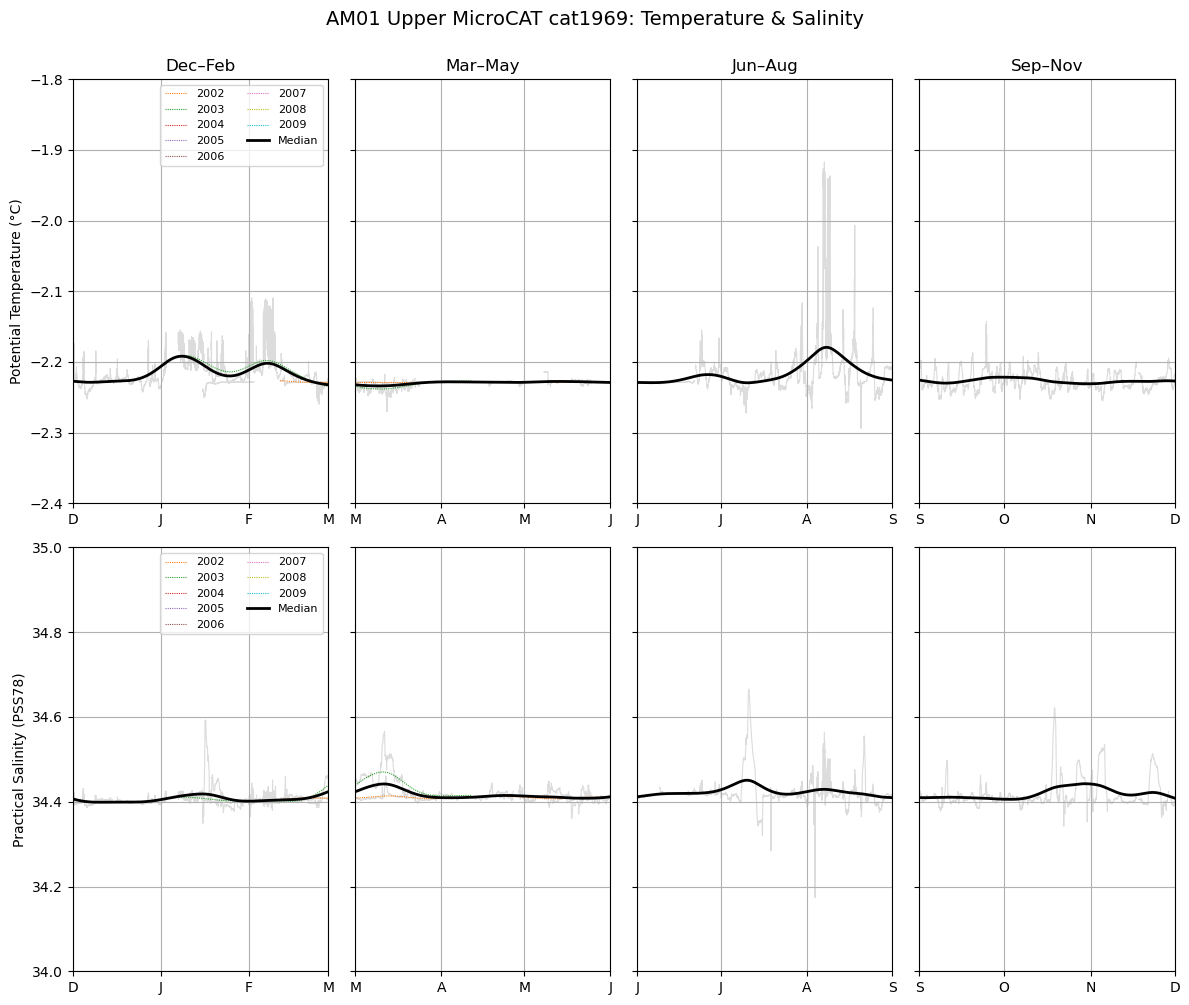

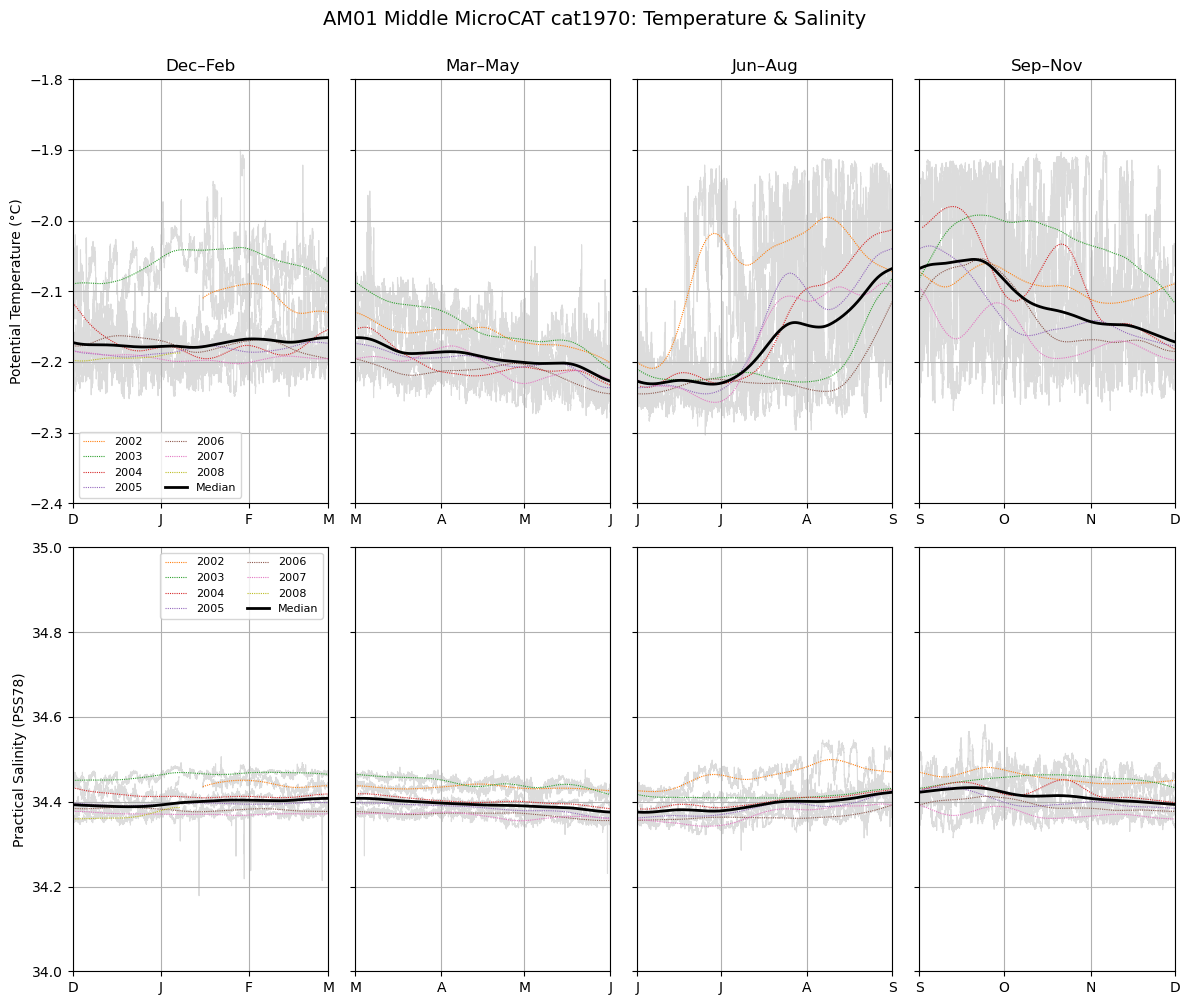

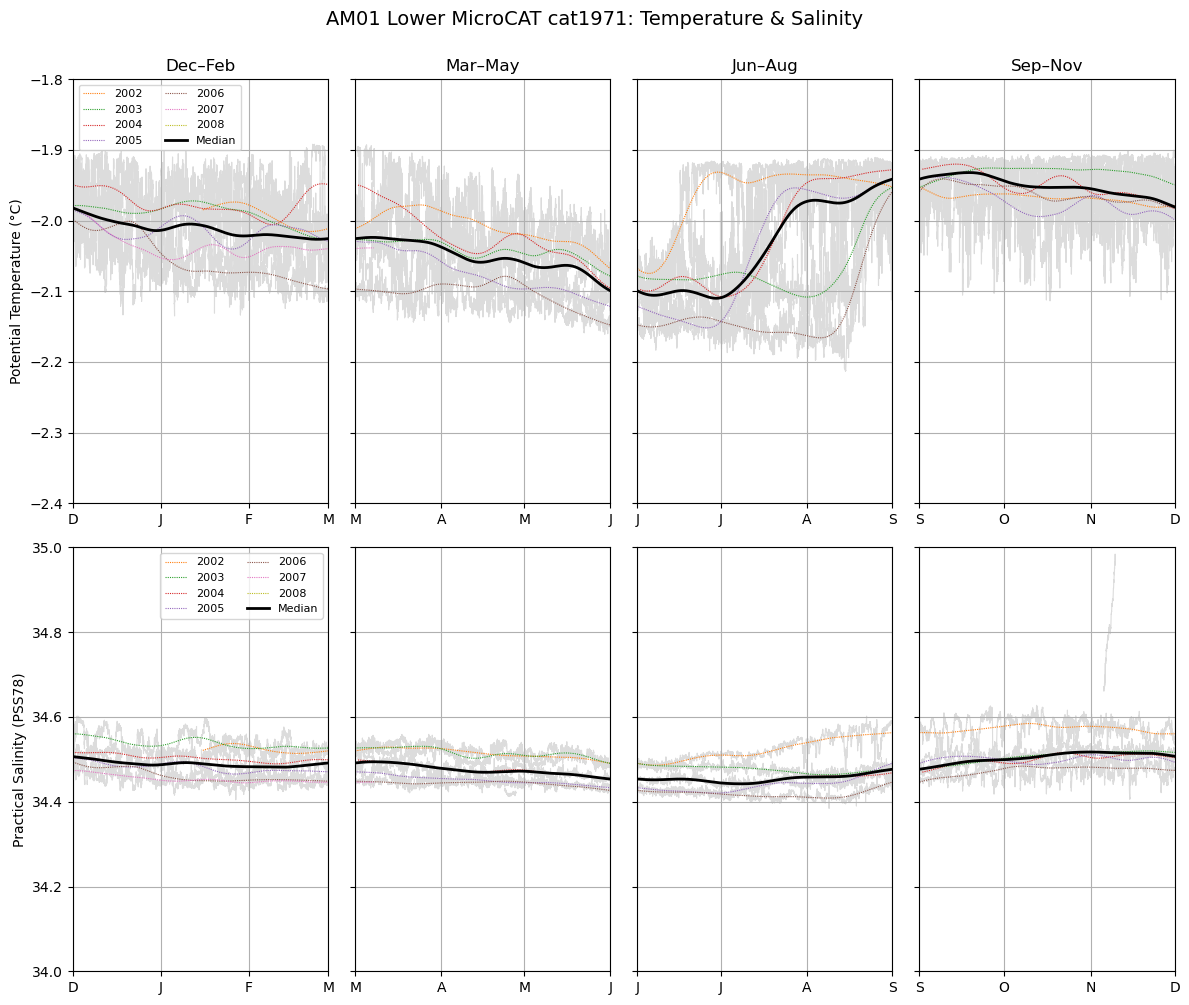

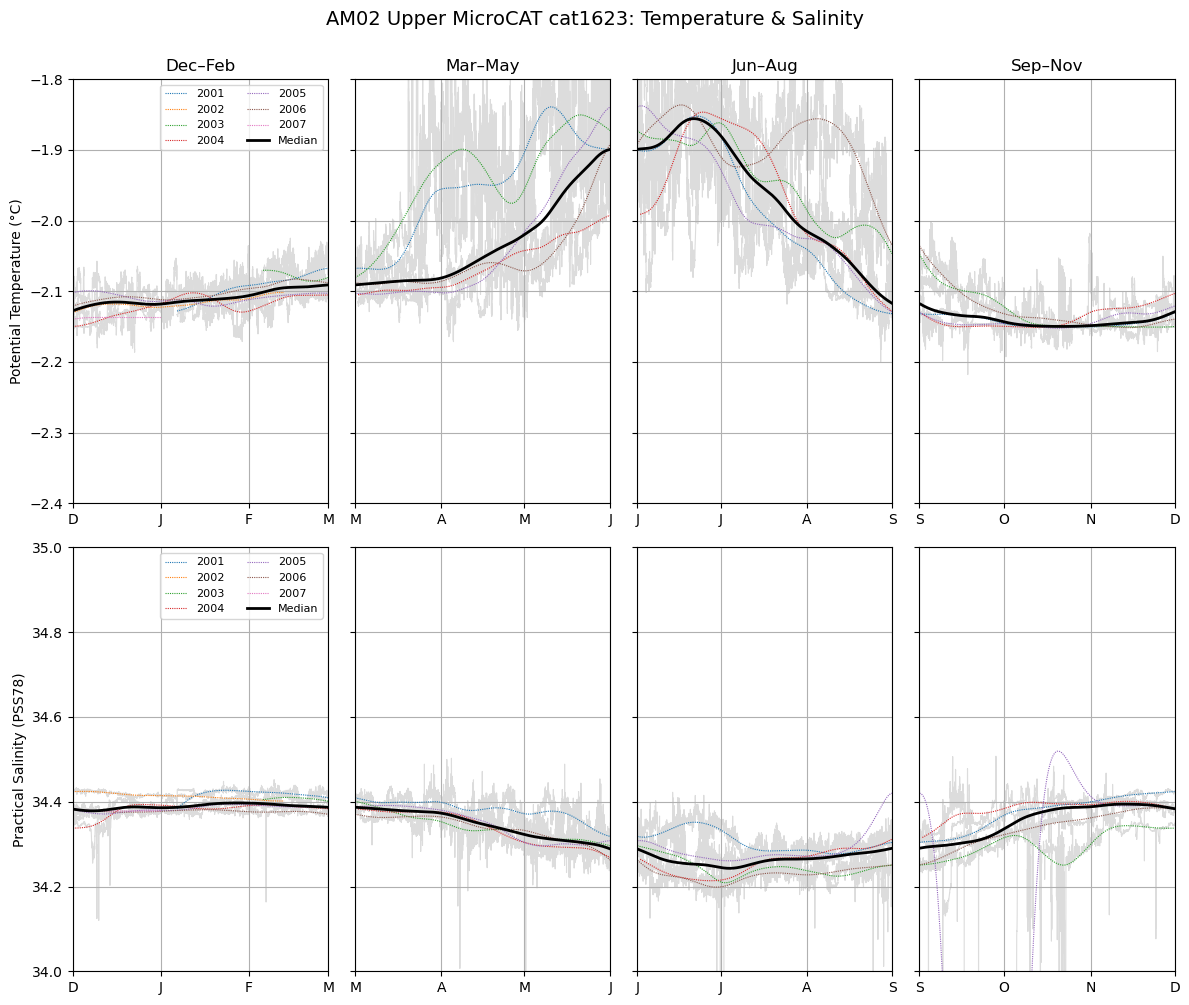

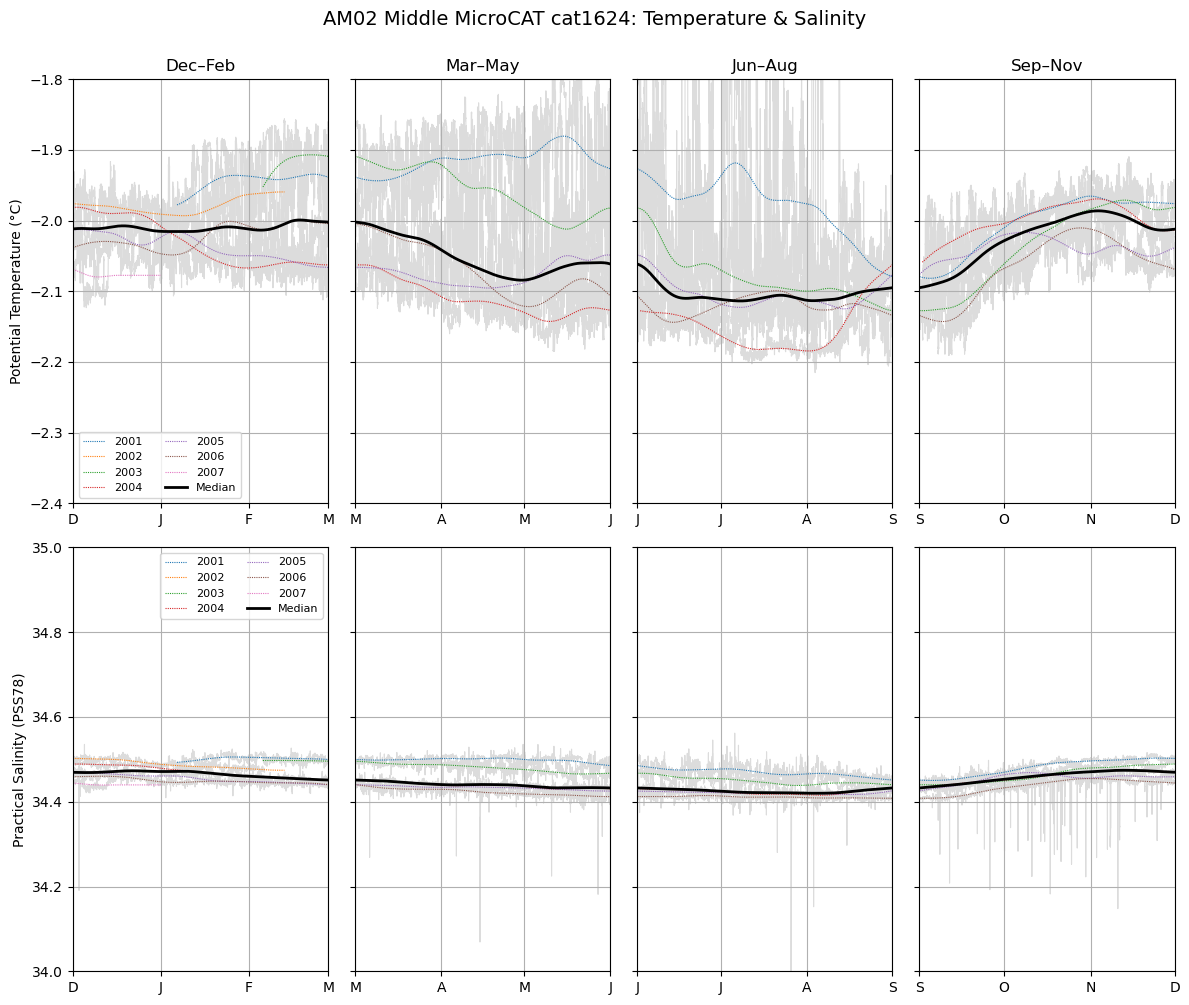

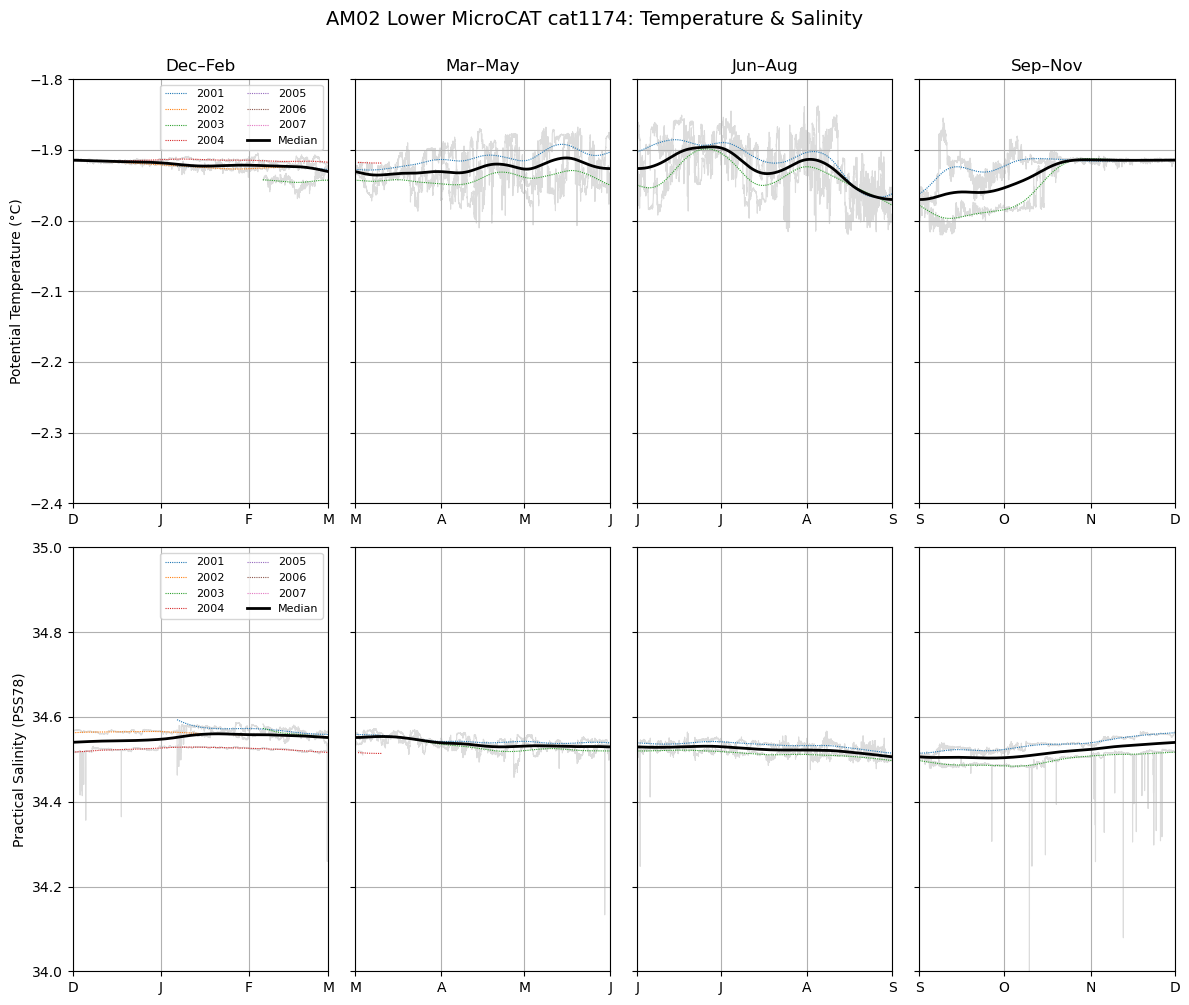

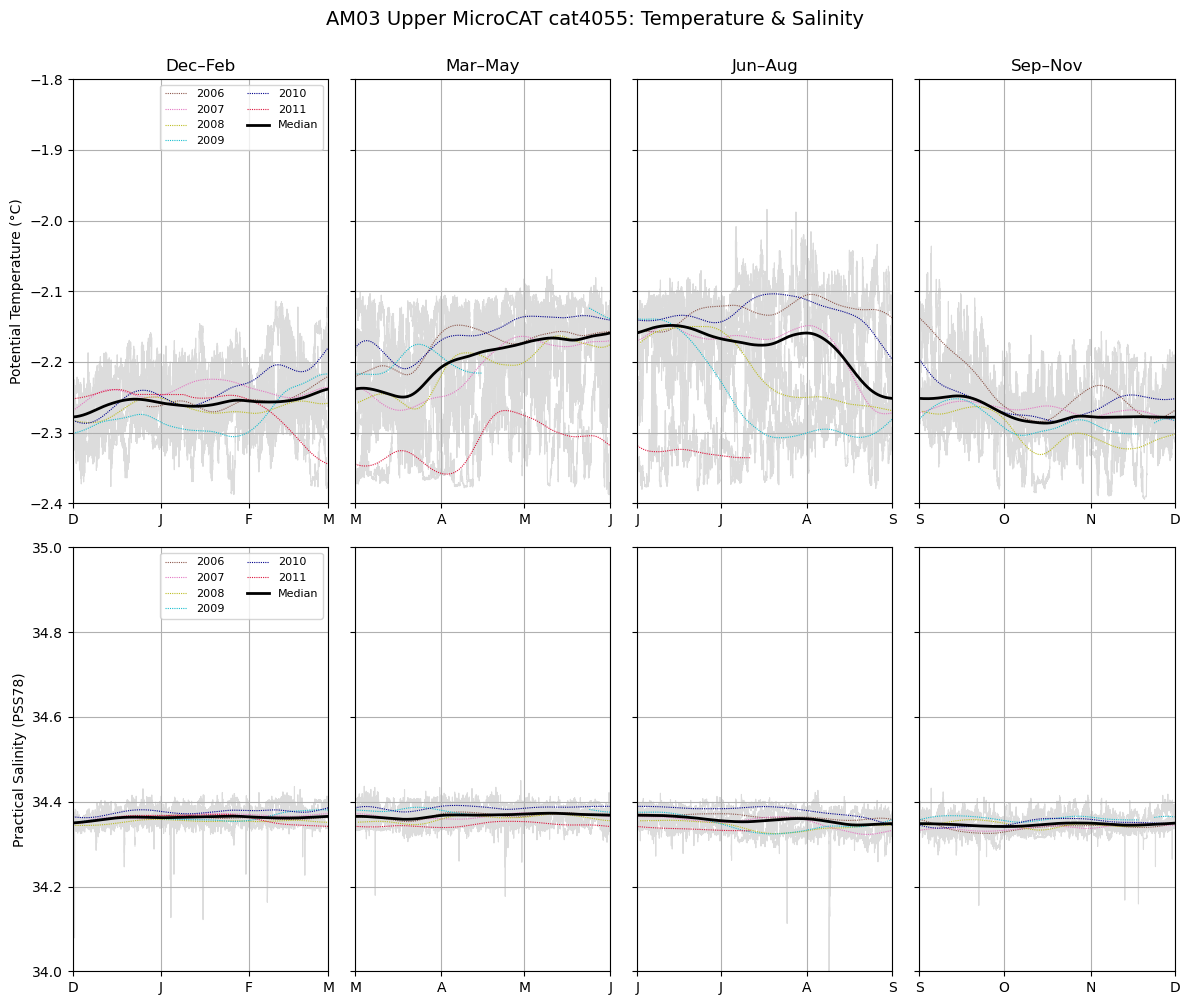

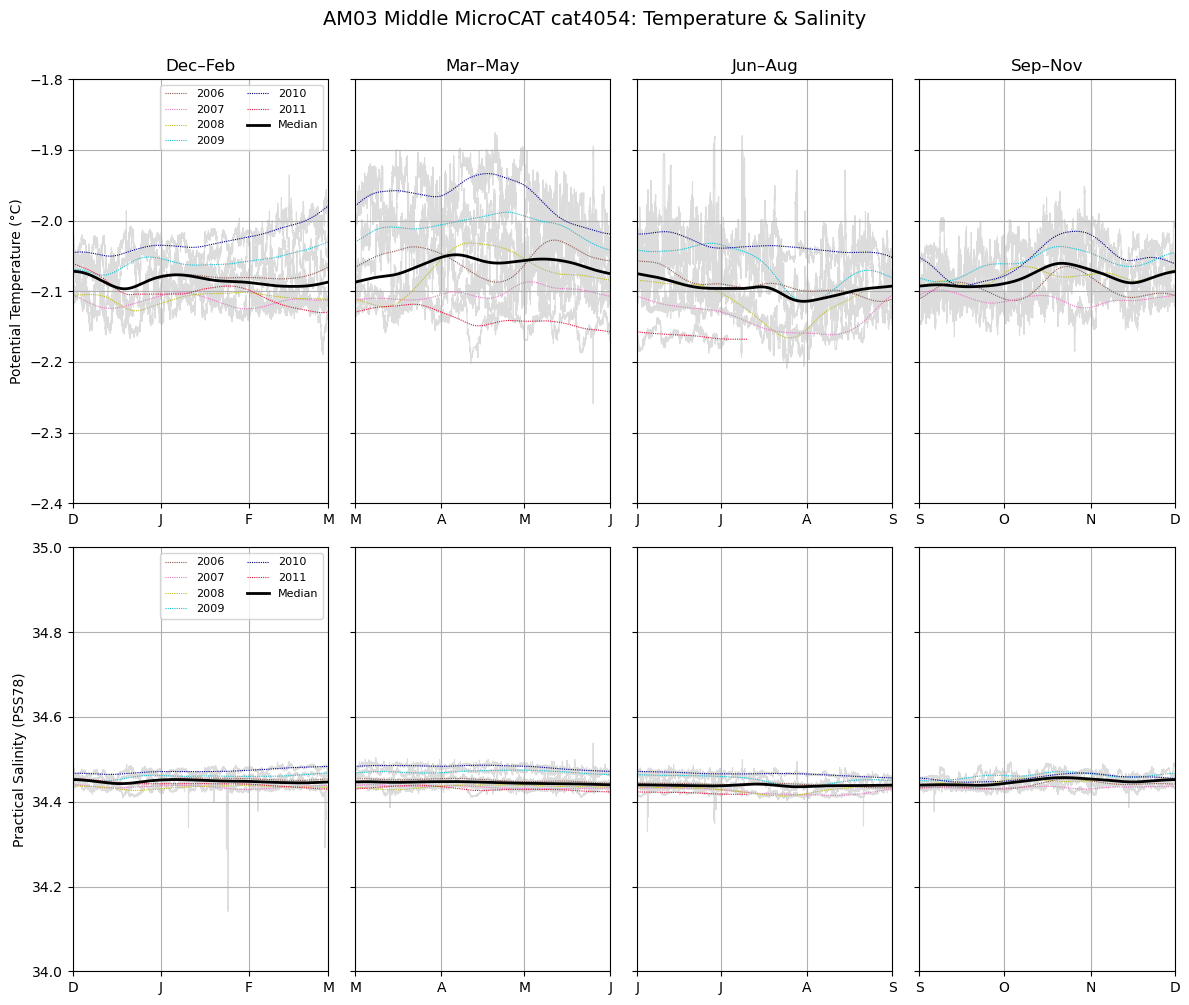

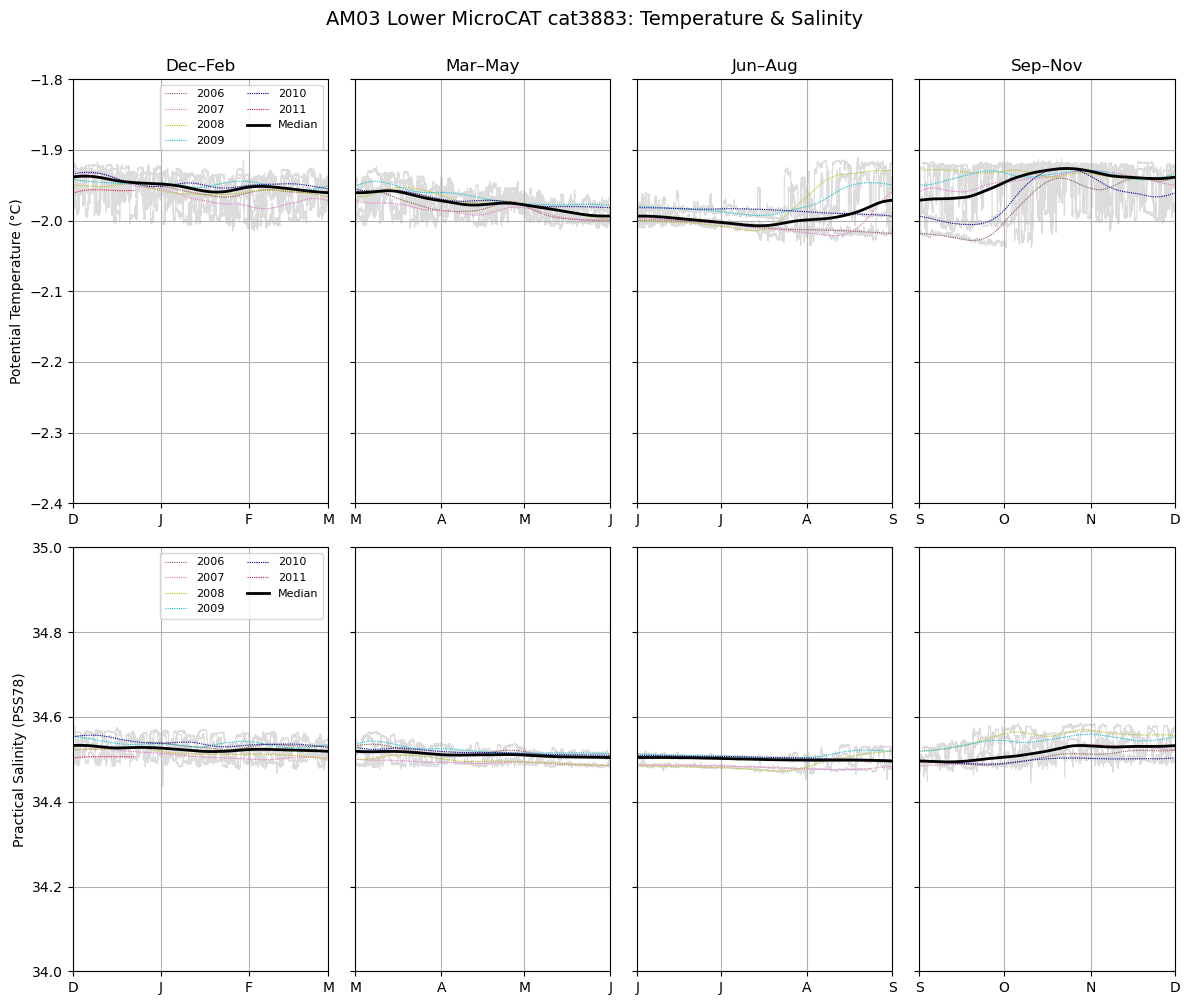

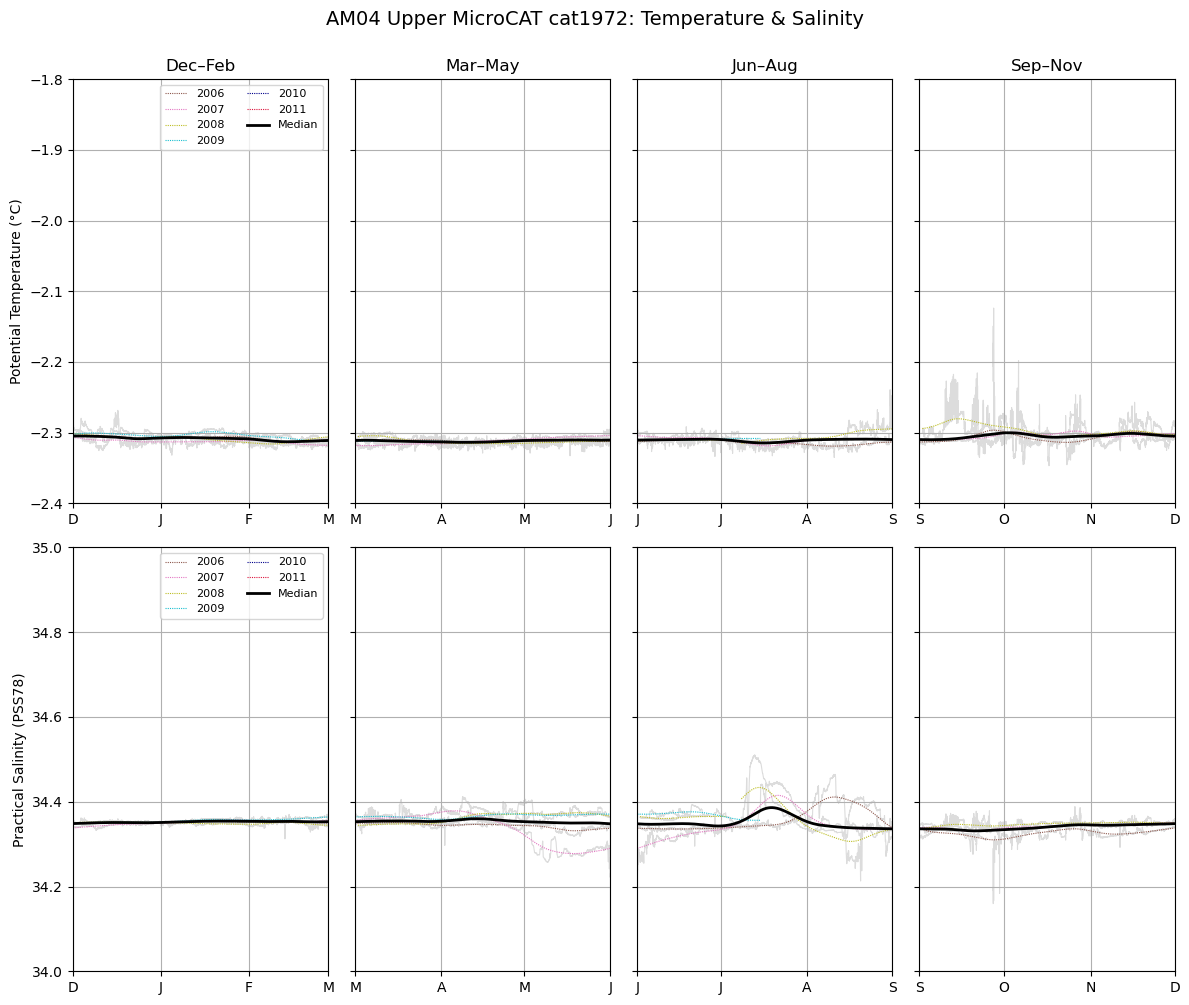

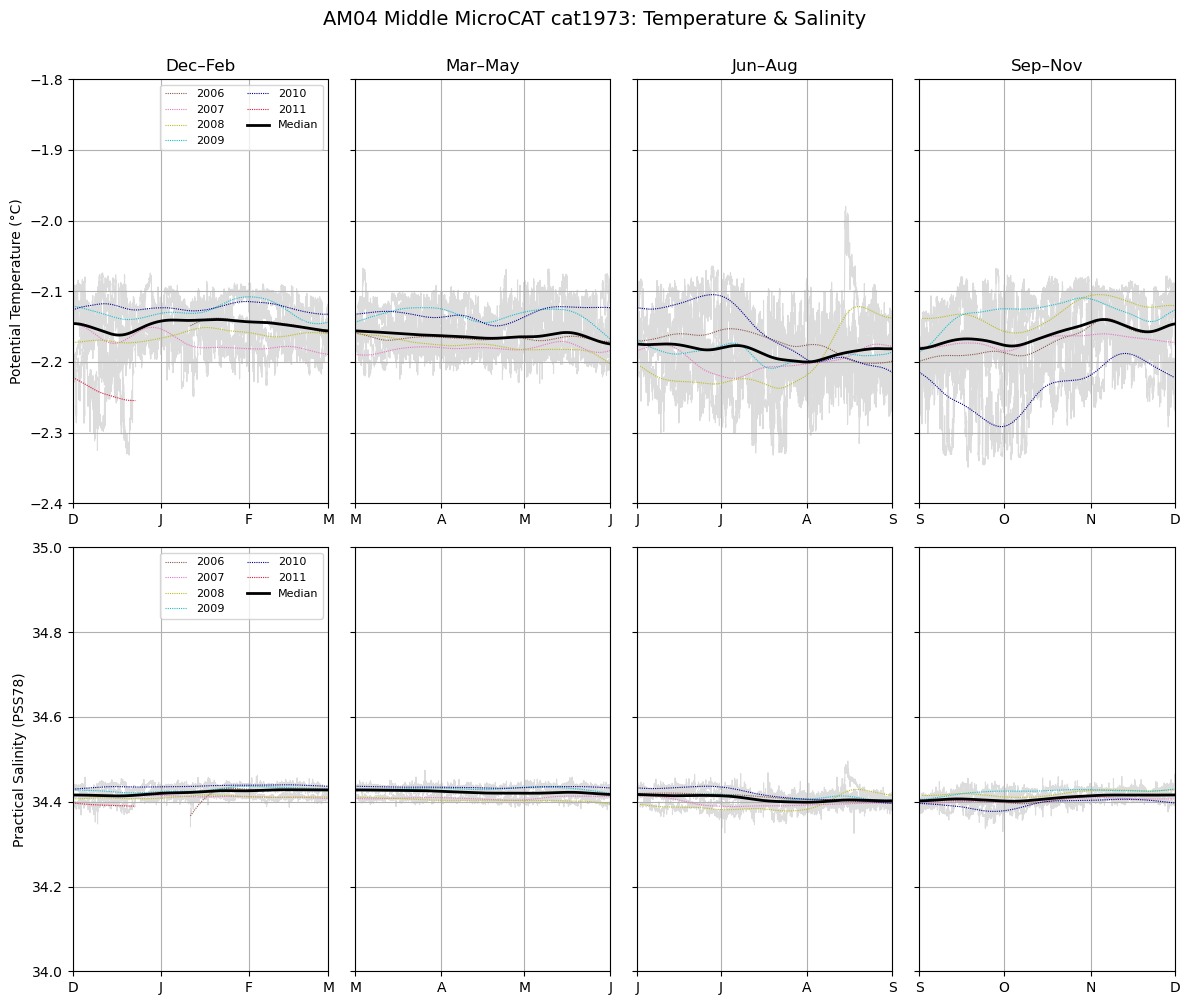

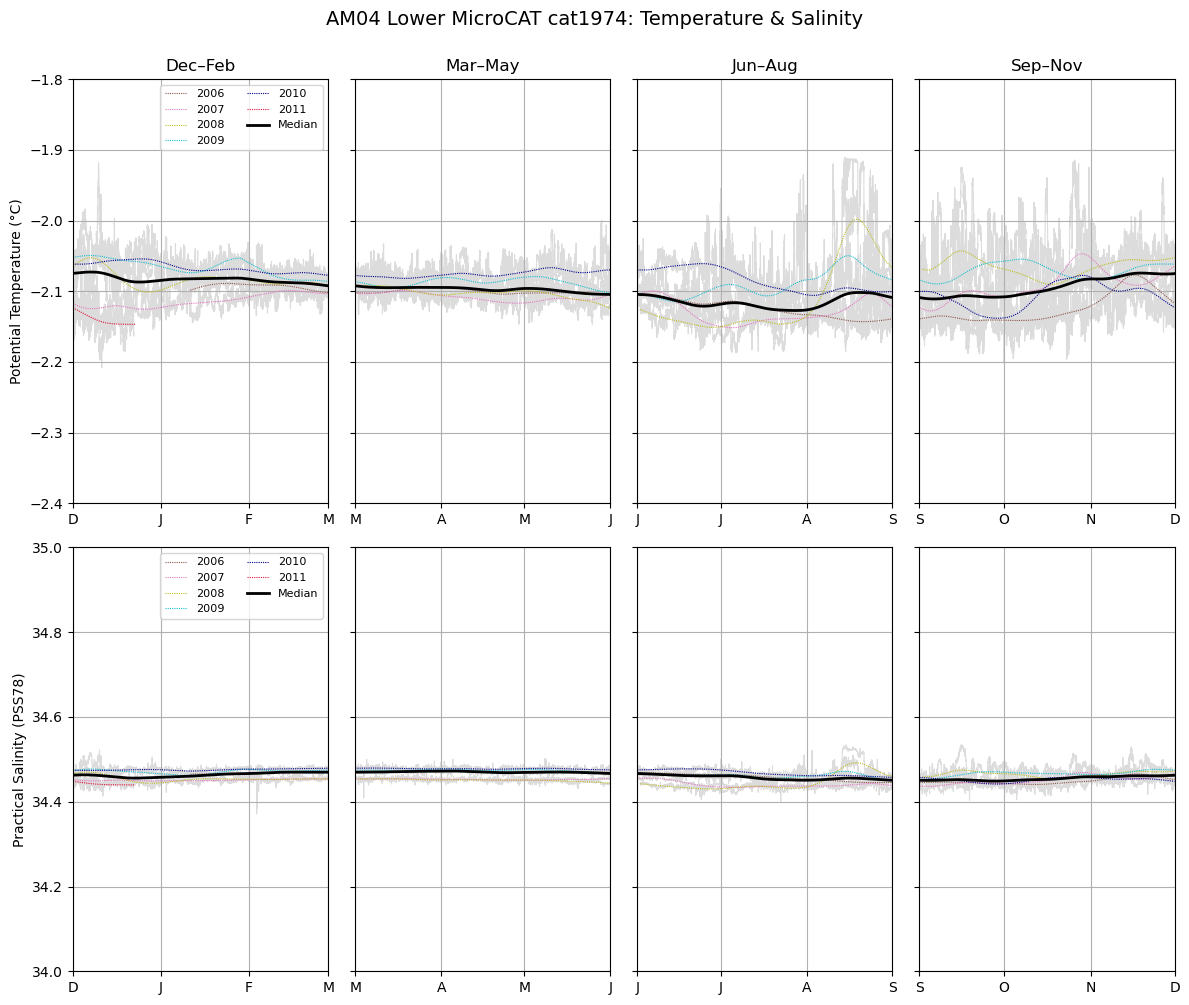

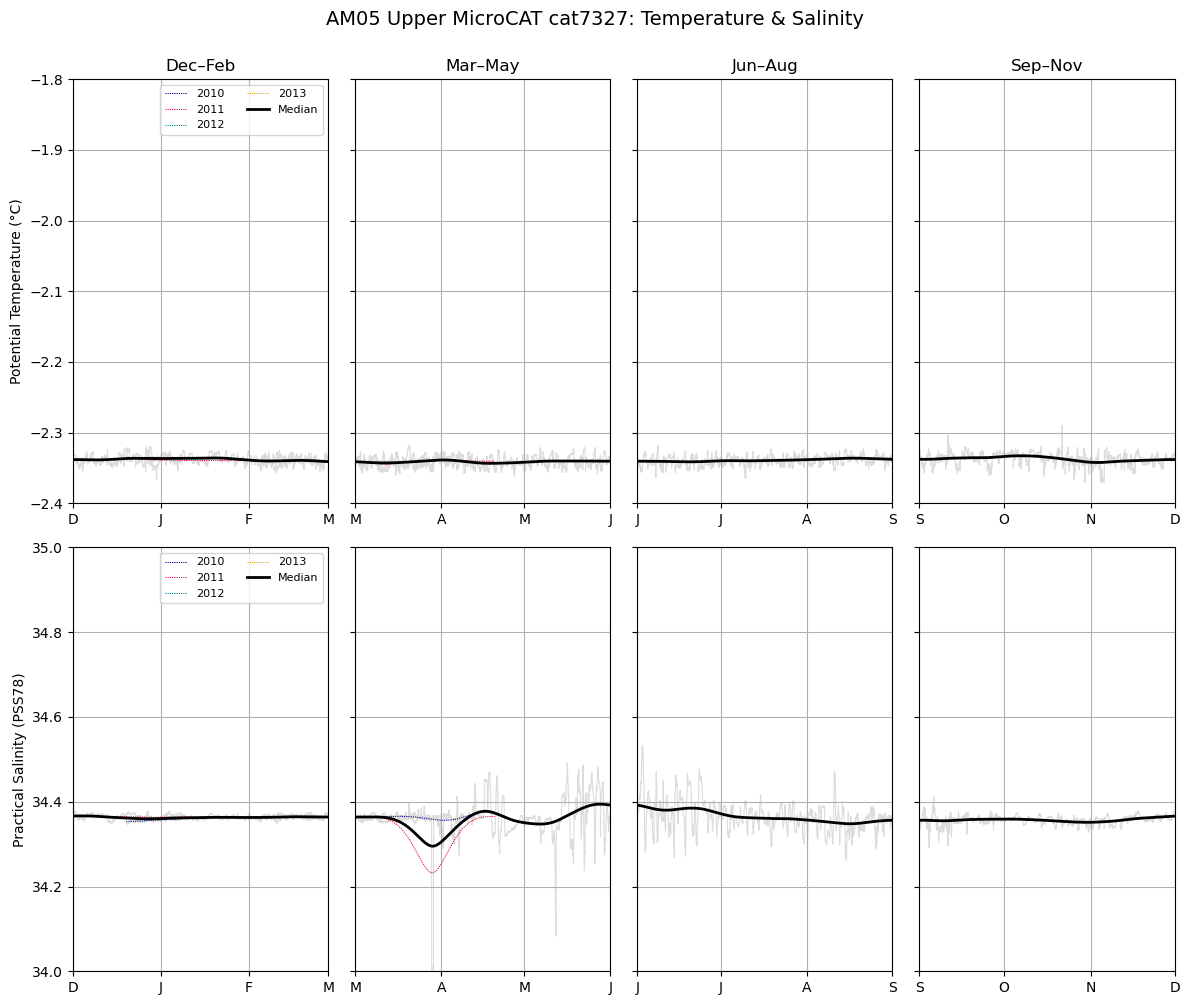

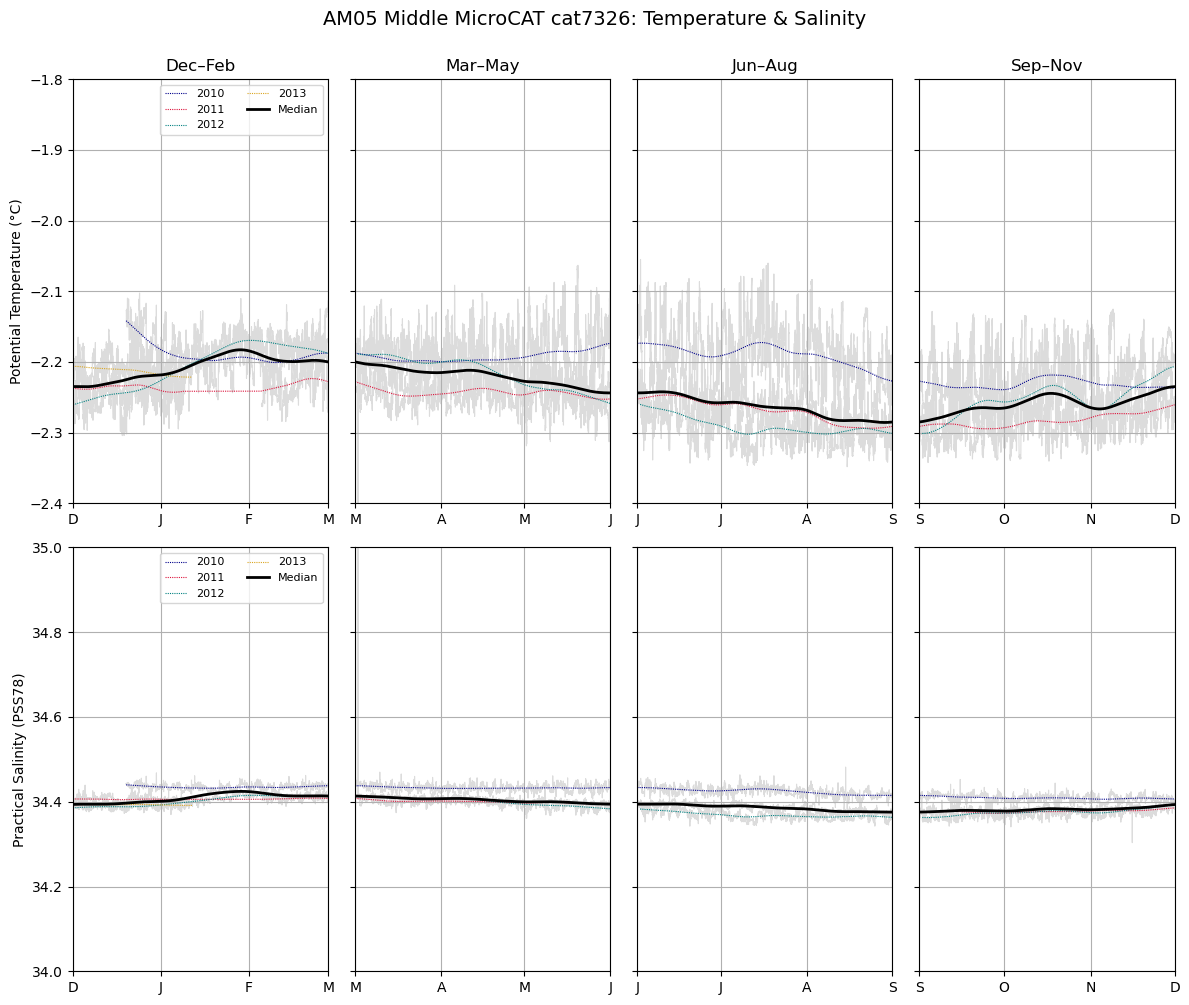

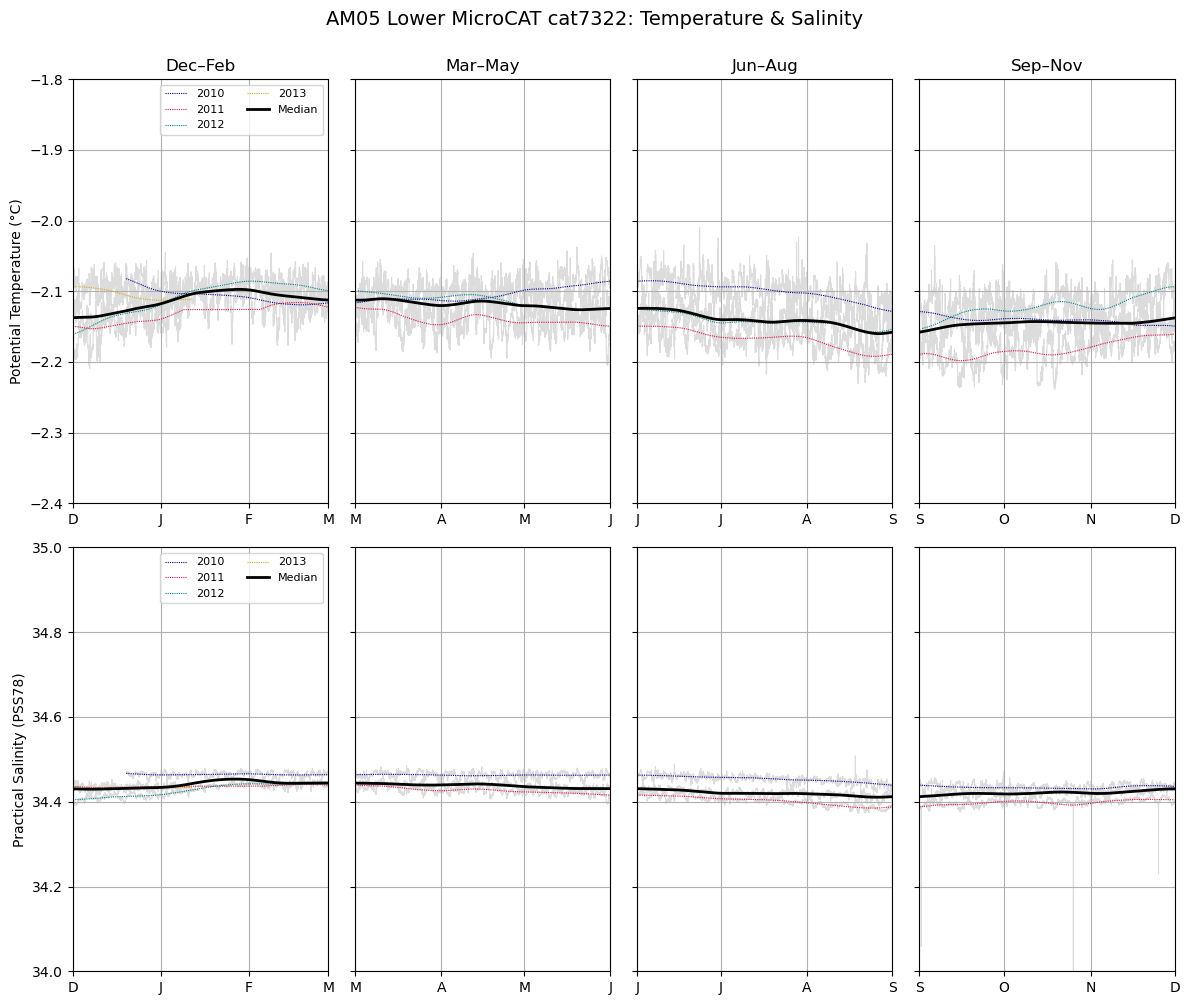

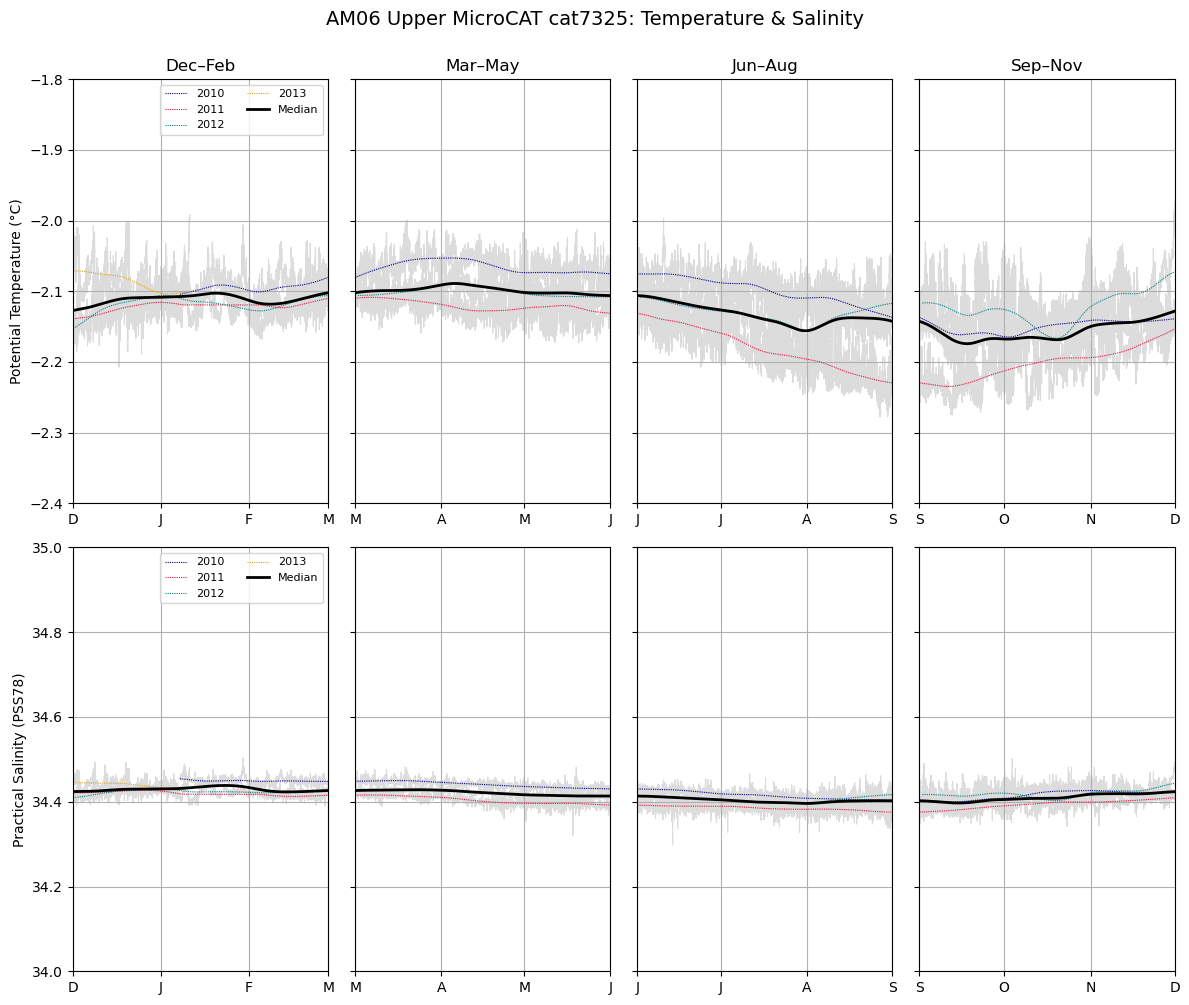

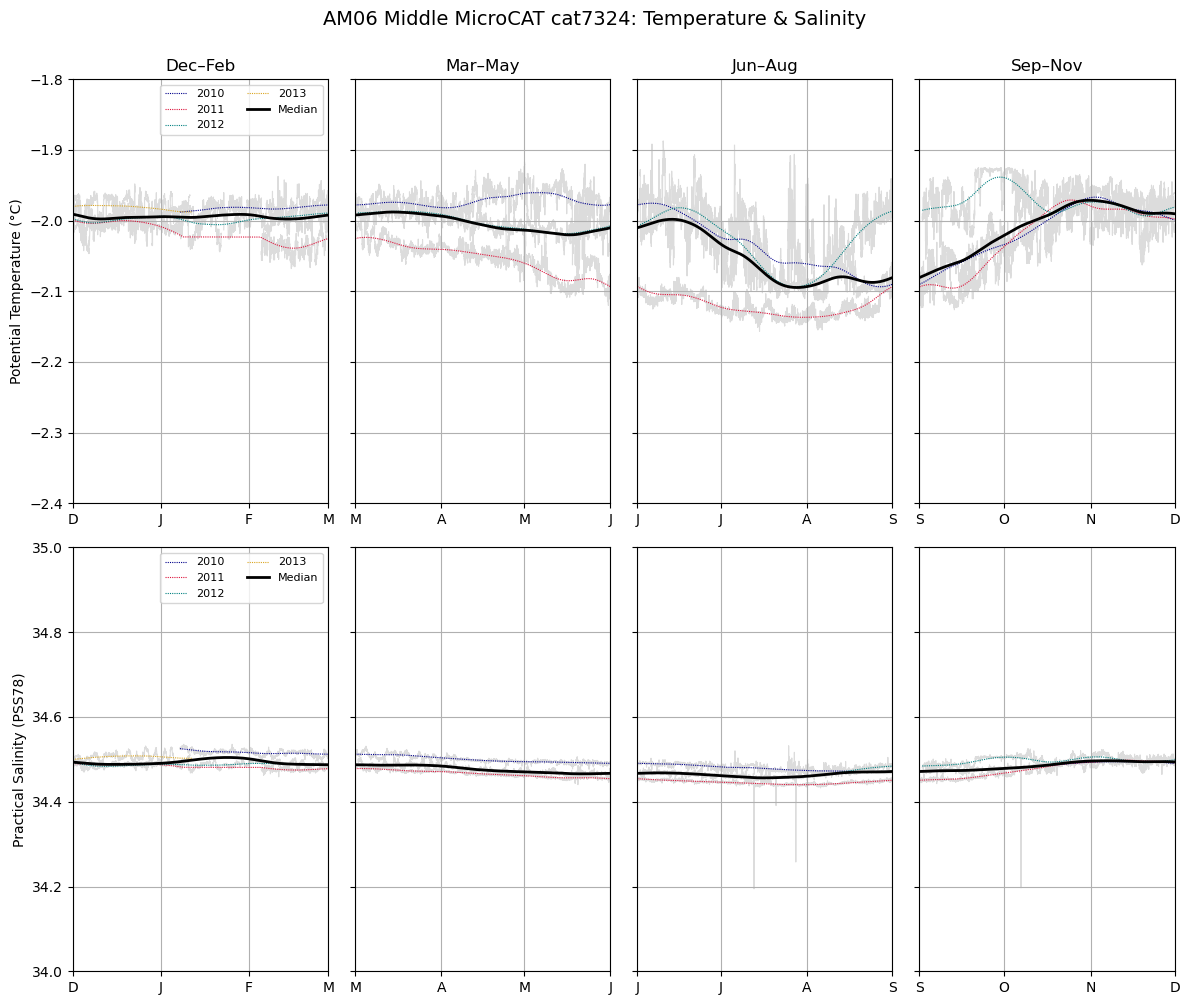

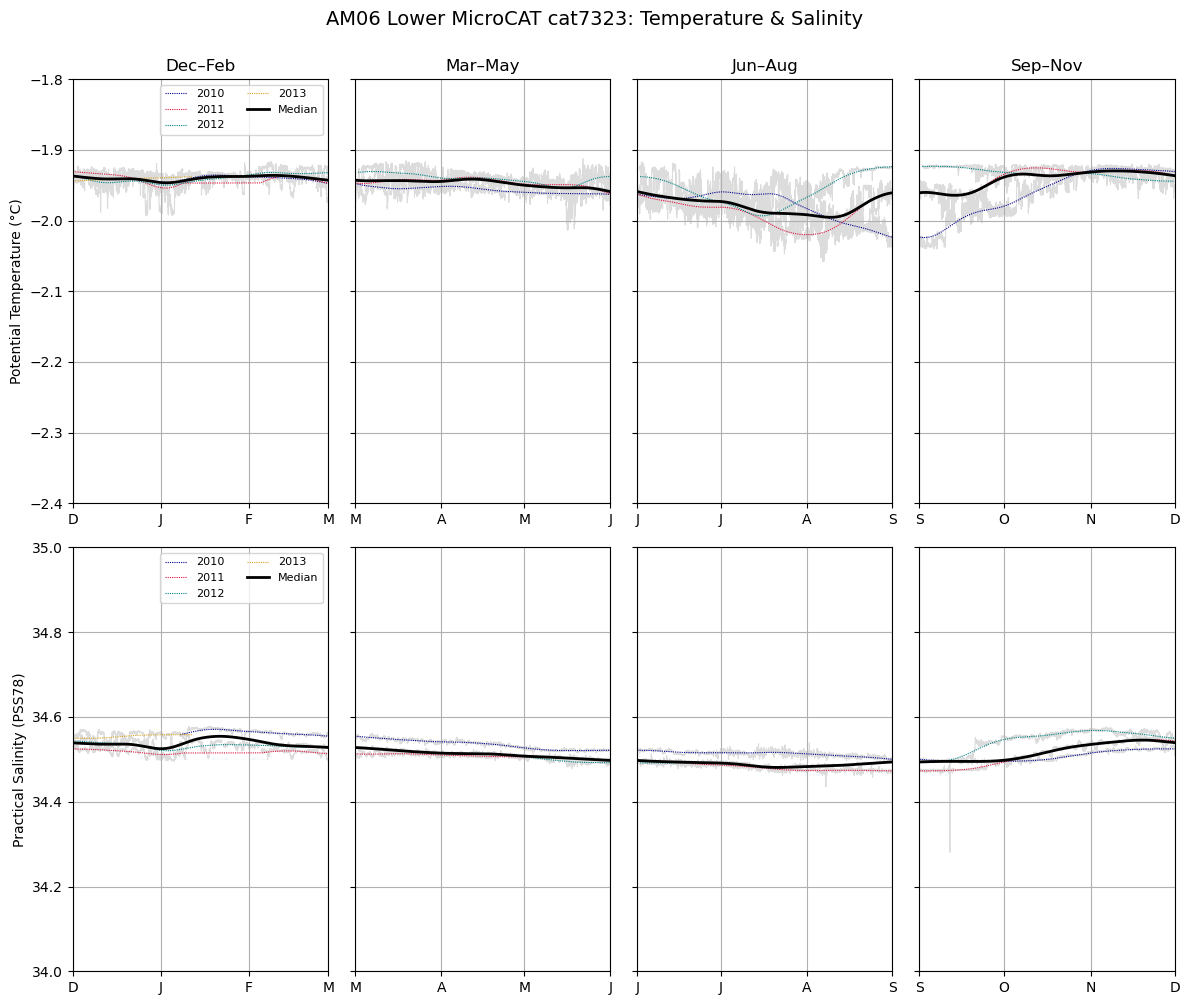

In [3]:
# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.4, -1.8)
ylim_sal = (34, 35)

boreholes = sorted(df_filtered["borehole"].unique())

for borehole in boreholes:
    df_bh = df_filtered[df_filtered["borehole"] == borehole]

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    for position in position_order:
        cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()

        for cat in cats:
            plot_season(df_filtered, borehole, cat, ylim_temp=ylim_temp, ylim_sal=ylim_sal)